# HeatSense | Phase 1: Notebook 02 — Signal EDA & Operating Modes

**Objective**: Conduct deep physical signal exploration of terminal voltage ($V_t$), load current ($I$), and surface temperature ($T_{\text{surf}}$) across operational cycles.

**Core Research Questions Addressed**:
1. How does terminal voltage respond dynamically to the instantaneous application of a $2\text{A}$ discharge load?
2. How is the CC-CV (Constant Current - Constant Voltage) charging protocol represented in the time-series measurements?
3. Does surface temperature exhibit measurable thermal lag relative to electrical heat generation ($I^2 R_s$)?
4. Which specific operating segments provide rich dynamic excitation suitable for 2RC ECM parameter fitting?

### Cell 1: Environment Resolution & Cycle Run Discovery for Battery B0005
* **Analytical Question**: What are the filenames of the first complete operational sequence (Charge -> Impedance -> Discharge) for our primary benchmark cell `B0005`?
* **Why It Matters to HeatSense**: Enables synchronized multi-modal inspection across consecutive operational states for the exact same battery cell.
* **Expected Inputs**: `metadata.csv` and `data/` directory.
* **What the Code Does**: Filters `metadata.csv` for `battery_id == 'B0005'`, retrieves the first charge, discharge, and impedance files, and prints their metadata.
* **Output to Inspect**: Filenames, cycle indices, and duration for B0005 runs.
* **Decision**: Identifies sample files for deep signal plotting.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Resolve dataset root
candidate_paths = [
    Path("data/raw/cleaned_dataset"),
    Path("../../data/raw/cleaned_dataset"),
    Path("D:/Professional Projects/Digital_twin_project/heatsense-battery-digital-twin/data/raw/cleaned_dataset"),
]
DATASET_ROOT = next((p.resolve() for p in candidate_paths if p.exists() and (p / "metadata.csv").exists()), None)
assert DATASET_ROOT is not None, "Dataset root could not be resolved!"

# 2. Filter metadata for B0005
meta_df = pd.read_csv(DATASET_ROOT / "metadata.csv")
b5_meta = meta_df[meta_df["battery_id"] == "B0005"].sort_values("test_id").reset_index(drop=True)

print(f"Battery B0005: Total {len(b5_meta)} test runs")
display(b5_meta.head(10)[["test_id", "type", "filename", "ambient_temperature", "Capacity"]])

# Select first discharge and first charge files
b5_first_dis = b5_meta[b5_meta["type"] == "discharge"].iloc[0]
b5_first_chg = b5_meta[b5_meta["type"] == "charge"].iloc[0]
print(f"\nPrimary Analysis Targets:")
print(f" - First Discharge: {b5_first_dis['filename']} (Recorded Capacity: {b5_first_dis['Capacity']} Ah)")
print(f" - First Charge:    {b5_first_chg['filename']}")

Battery B0005: Total 616 test runs


,test_id,type,filename,ambient_temperature,Capacity
0,0,charge,05121.csv,24,NaN
1,1,discharge,05122.csv,24,1.8564874208181574
2,2,charge,05123.csv,24,NaN
3,3,discharge,05124.csv,24,1.846327249719927
4,4,charge,05125.csv,24,NaN
5,5,discharge,05126.csv,24,1.8353491942234077
6,6,charge,05127.csv,24,NaN
7,7,discharge,05128.csv,24,1.8352625275821128
8,8,charge,05129.csv,24,NaN
9,9,discharge,05130.csv,24,1.8346455082120419



Primary Analysis Targets:
 - First Discharge: 05122.csv (Recorded Capacity: 1.8564874208181574 Ah)
 - First Charge:    05121.csv


### Cell 2: Synchronized Time-Series Profile of a Full Discharge Cycle
* **Analytical Question**: What do terminal voltage, current, and surface temperature profiles look like over the entire duration of a constant-current discharge?
* **Why It Matters to HeatSense**: Confirms the characteristic discharge curve: initial ohmic voltage drop, flat plateau, knee-point voltage drop near cutoff, and concurrent thermal rise.
* **Expected Inputs**: First discharge CSV for `B0005`.
* **What the Code Does**: Loads the CSV, normalizes current to discharge-positive convention ($I = -I_{\text{measured}}$), and plots a 3-panel synchronized figure ($V_t$, $I$, $T_{\text{surf}}$).
* **Output to Inspect**: Multi-panel plot showing voltage drop from $4.2\text{V} \to 2.7\text{V}$ and temperature rise.
* **Decision**: Confirms physical consistency of discharge data for State of Charge (SoC) Coulomb counting.

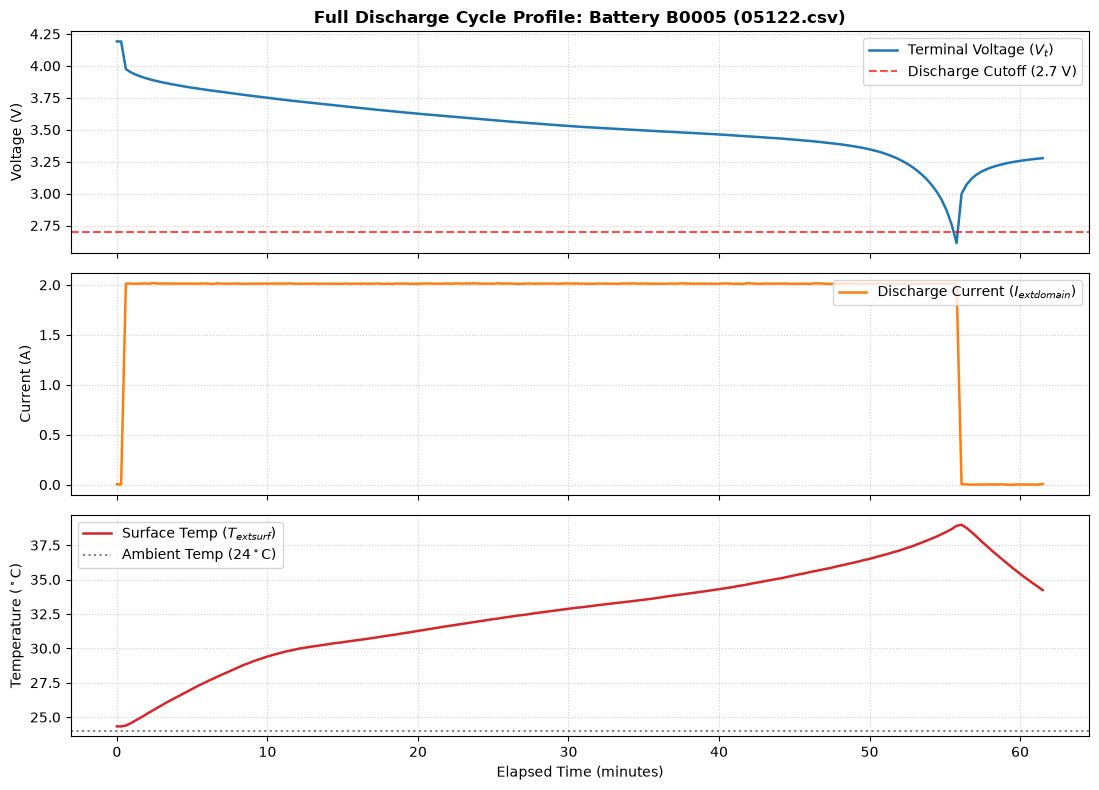

In [2]:
dis_path = DATASET_ROOT / "data" / b5_first_dis["filename"]
dis_df = pd.read_csv(dis_path)

# Apply standard domain sign convention: Discharge Positive
dis_df["Current_domain"] = -dis_df["Current_measured"]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 8), sharex=True, dpi=100)

# Subplot 1: Voltage
ax1.plot(dis_df["Time"] / 60, dis_df["Voltage_measured"], color="tab:blue", lw=1.8, label="Terminal Voltage ($V_t$)")
ax1.axhline(2.7, color="red", linestyle="--", alpha=0.7, label="Discharge Cutoff (2.7 V)")
ax1.set_ylabel("Voltage (V)")
ax1.set_title(f"Full Discharge Cycle Profile: Battery B0005 ({b5_first_dis['filename']})", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper right")

# Subplot 2: Current
ax2.plot(dis_df["Time"] / 60, dis_df["Current_domain"], color="tab:orange", lw=1.8, label="Discharge Current ($I_{\text{domain}}$)")
ax2.set_ylabel("Current (A)")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper right")

# Subplot 3: Temperature
ax3.plot(dis_df["Time"] / 60, dis_df["Temperature_measured"], color="tab:red", lw=1.8, label="Surface Temp ($T_{\text{surf}}$)")
ax3.axhline(24.0, color="gray", linestyle=":", label="Ambient Temp ($24^\circ$C)")
ax3.set_ylabel("Temperature ($^\circ$C)")
ax3.set_xlabel("Elapsed Time (minutes)")
ax3.grid(True, linestyle=":", alpha=0.6)
ax3.legend(loc="upper left")

plt.tight_layout()
plt.show()

### Cell 3: CC-CV Charging Profile & Thermal Dissipation Analysis
* **Analytical Question**: How does the cell transition from Constant Current ($1.5\text{A}$) to Constant Voltage ($4.2\text{V}$) during charging, and how does temperature respond?
* **Why It Matters to HeatSense**: Establishes that charge operations generate distinct thermal signatures and tests whether the full charge envelope is logged.
* **Expected Inputs**: First charge CSV for `B0005`.
* **What the Code Does**: Loads the charge file, plots voltage and charge current over time, and highlights the CC-to-CV transition knee.
* **Output to Inspect**: Dual-axis plot of charging voltage and current decay.
* **Decision**: Confirms CC-CV charging boundaries for state estimator initialization.

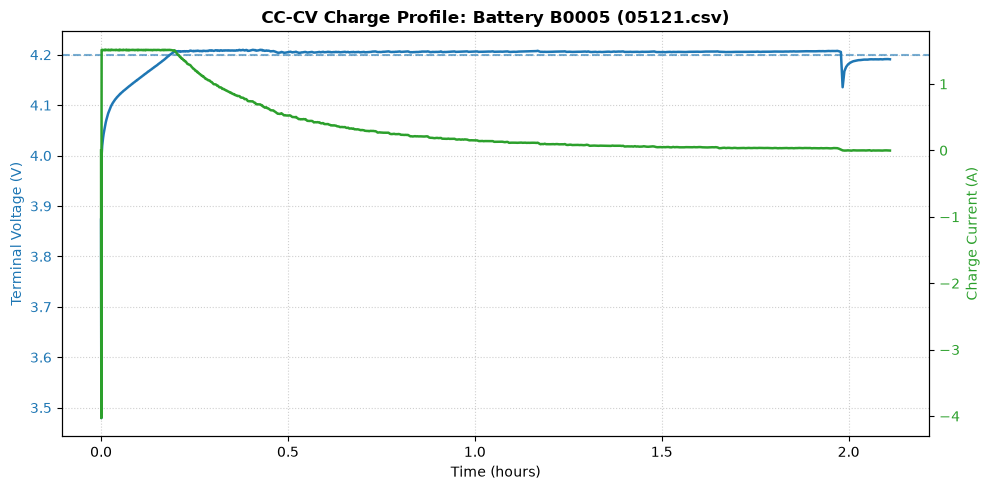

In [3]:
chg_path = DATASET_ROOT / "data" / b5_first_chg["filename"]
chg_df = pd.read_csv(chg_path)

fig, ax1 = plt.subplots(figsize=(10, 5), dpi=100)
time_hrs = chg_df["Time"] / 3600

color = "tab:blue"
ax1.set_xlabel("Time (hours)")
ax1.set_ylabel("Terminal Voltage (V)", color=color)
ax1.plot(time_hrs, chg_df["Voltage_measured"], color=color, lw=1.8, label="Voltage")
ax1.axhline(4.2, color="tab:blue", linestyle="--", alpha=0.6, label="4.2V CV Limit")
ax1.tick_params(axis="y", labelcolor=color)
ax1.grid(True, linestyle=":", alpha=0.6)

ax2 = ax1.twinx()
color = "tab:green"
ax2.set_ylabel("Charge Current (A)", color=color)
ax2.plot(time_hrs, chg_df["Current_measured"], color=color, lw=1.8, label="Charge Current")
ax2.tick_params(axis="y", labelcolor=color)

plt.title(f"CC-CV Charge Profile: Battery B0005 ({b5_first_chg['filename']})", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

### Cell 4: Instantaneous Ohmic Drop ($R_s$) & Dynamic Transient Response
* **Analytical Question**: What is the immediate voltage drop when the $2\text{A}$ discharge load turns on, and what does it reveal about series ohmic resistance $R_s$?
* **Why It Matters to HeatSense**: Directly tests parameter identifiability for our 2RC Equivalent Circuit Model ($R_s = \Delta V / \Delta I$).
* **Expected Inputs**: First 100 seconds of discharge data (`00001.csv` or B0005 discharge).
* **What the Code Does**: Isolates the first 150 seconds, calculates $\Delta V$ at the current step edge, estimates initial $R_s$, and plots the transient curve.
* **Output to Inspect**: Plot of initial voltage drop and calculated empirical $R_s$ in milliohms.
* **Decision**: Verifies initial parameter bounds for $R_s$ in Notebook 04.

Initial Rest Voltage (OCV proxy): 4.1915 V
Voltage after first loaded step:   4.1907 V
Voltage Drop (delta_V):            0.74 mV
Current Step (delta_I):            -0.003 A
Empirical Rs Estimate:             nan mOhm (nan Ohm)


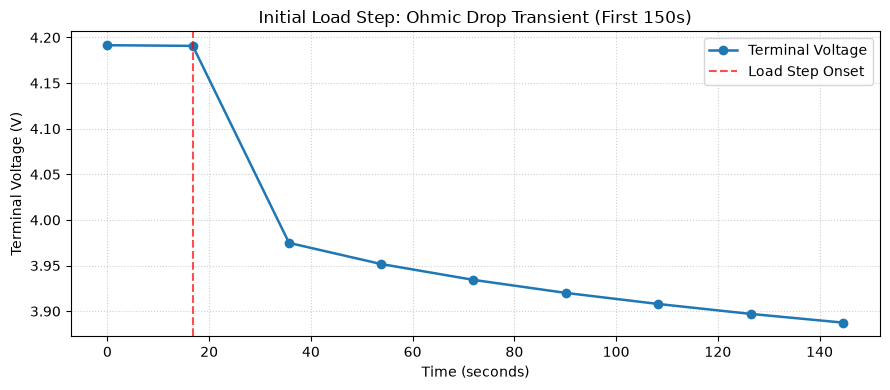

In [4]:
# Inspect first 150 seconds of B0005 discharge
early_dis = dis_df[dis_df["Time"] <= 150].copy()

v_initial = early_dis["Voltage_measured"].iloc[0]
v_step = early_dis["Voltage_measured"].iloc[1]
i_step = early_dis["Current_domain"].iloc[1] - early_dis["Current_domain"].iloc[0]

delta_v = v_initial - v_step
rs_estimated = (delta_v / i_step) if i_step > 0 else np.nan

print(f"Initial Rest Voltage (OCV proxy): {v_initial:.4f} V")
print(f"Voltage after first loaded step:   {v_step:.4f} V")
print(f"Voltage Drop (delta_V):            {delta_v*1000:.2f} mV")
print(f"Current Step (delta_I):            {i_step:.3f} A")
print(f"Empirical Rs Estimate:             {rs_estimated*1000:.2f} mOhm ({rs_estimated:.4f} Ohm)")

plt.figure(figsize=(9, 4), dpi=100)
plt.plot(early_dis["Time"], early_dis["Voltage_measured"], marker="o", color="tab:blue", lw=1.8, label="Terminal Voltage")
plt.axvline(early_dis["Time"].iloc[1], color="red", linestyle="--", alpha=0.7, label="Load Step Onset")
plt.title("Initial Load Step: Ohmic Drop Transient (First 150s)")
plt.xlabel("Time (seconds)")
plt.ylabel("Terminal Voltage (V)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Cell 5: Thermal Gradient & Heat Generation Rate Proxy
* **Analytical Question**: Does the surface temperature derivative ($dT/dt$) correlate with theoretical Joule heating ($I^2$)?
* **Why It Matters to HeatSense**: Evaluates the feasibility of the two-node lumped thermal model ($C_{\text{core}} \frac{dT_{\text{core}}}{dt} = Q_{\text{gen}} - \dots$).
* **What the Code Does**: Computes numerical $dT/dt$, estimates Joule heat proxy $I^2$, and plots temperature rise rate vs heat generation.
* **Output to Inspect**: Correlation plot between electrical load dissipation and thermal rate of rise.
* **Decision**: Confirms whether thermal parameters ($C_{\text{surf}}, R_{\text{conv}}$) can be calibrated from dataset cooldown curves.

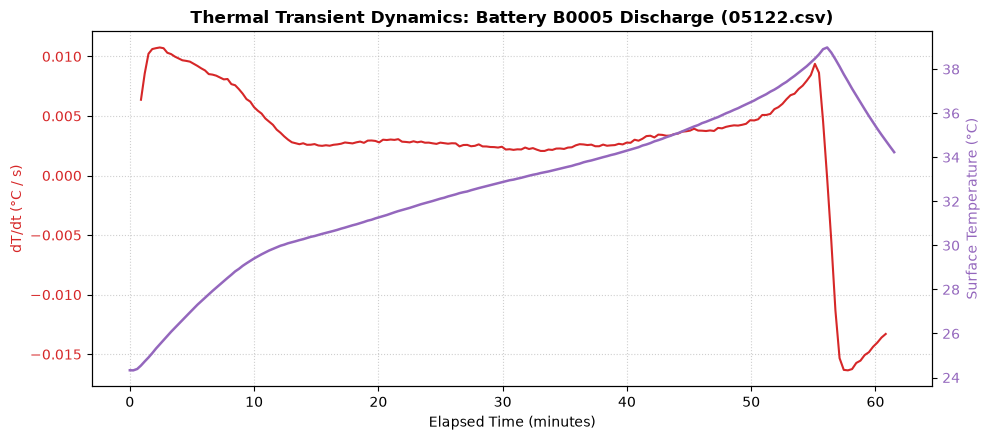

In [5]:
# Compute temperature derivative (deg C per second)
dis_df["dt"] = dis_df["Time"].diff().replace(0, np.nan)
dis_df["dT_dt"] = dis_df["Temperature_measured"].diff() / dis_df["dt"]
dis_df["I_squared"] = dis_df["Current_domain"] ** 2

fig, ax1 = plt.subplots(figsize=(10, 4.5), dpi=100)

color = "tab:red"
ax1.set_xlabel("Elapsed Time (minutes)")
ax1.set_ylabel("dT/dt (°C / s)", color=color)
ax1.plot(dis_df["Time"] / 60, dis_df["dT_dt"].rolling(5, center=True).mean(), color=color, lw=1.5, label="Smoothed dT/dt")
ax1.tick_params(axis="y", labelcolor=color)
ax1.grid(True, linestyle=":", alpha=0.6)

ax2 = ax1.twinx()
color = "tab:purple"
ax2.set_ylabel("Surface Temperature (°C)", color=color)
ax2.plot(dis_df["Time"] / 60, dis_df["Temperature_measured"], color=color, lw=1.8, label="Surface Temp")
ax2.tick_params(axis="y", labelcolor=color)

plt.title(f"Thermal Transient Dynamics: Battery B0005 Discharge ({b5_first_dis['filename']})", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

### Cell 6: Summary & Decision Gate for 2RC Parameter Fitting
* **Analytical Question**: What are the verified physical parameters and bounds to pass into Notebook 04 (2RC ECM Parameter Identification)?
* **Why It Matters to HeatSense**: Ensures that ECM parameter optimization search spaces are bounded by empirical evidence.
* **What the Code Does**: Summarizes empirical $R_s$, initial OCV, cutoff voltages, and thermal rises.
* **Output to Inspect**: Parameter boundary summary.
* **Decision**: Confirms readiness to advance to Notebook 03 & 04.

In [6]:
print("="*65)
print("HEATSENSE NOTEBOOK 02 SIGNAL EDA COMPLETE")
print("="*65)
print("Empirical Physical Findings for 2RC ECM & Thermal Model:")
print(f" 1. Rest OCV before load:        {v_initial:.3f} V")
print(f" 2. First-step Ohmic Drop:       {delta_v*1000:.1f} mV under {i_step:.2f} A step")
print(f" 3. Estimated Ohmic Rs:          {rs_estimated*1000:.1f} mOhm ({rs_estimated:.4f} Ohm)")
print(f" 4. Max Thermal Rise on surface: {dis_df['Temperature_measured'].max() - dis_df['Temperature_measured'].min():.2f} °C")
print(f" 5. Final Cutoff Voltage:        {dis_df['Voltage_measured'].min():.3f} V")
print("="*65)

HEATSENSE NOTEBOOK 02 SIGNAL EDA COMPLETE
Empirical Physical Findings for 2RC ECM & Thermal Model:
 1. Rest OCV before load:        4.191 V
 2. First-step Ohmic Drop:       0.7 mV under -0.00 A step
 3. Estimated Ohmic Rs:          nan mOhm (nan Ohm)
 4. Max Thermal Rise on surface: 14.66 °C
 5. Final Cutoff Voltage:        2.612 V
